# DEEP LEARNING: ỨNG DỤNG MẠNG NO-RON TÍCH CHẬP TRONG NHẬN DẠNG BIỂU CẢM
Pipeline tối ưu:
- Sử dụng bộ dữ liệu **FERPlus**.
- Loại bỏ hoàn toàn nhãn nhiễu và ảnh rác (Unknown / Not a Face).
- Tự động phát hiện cấu trúc thư mục FERPlus trên Kaggle.
- So sánh Baseline CNN vs Improved CNN (GlobalAveragePooling2D + L2) vs MobileNetV3-Small (Transfer Learning).

In [1]:
import os
import random
import json
import cv2
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix, f1_score, balanced_accuracy_score
from sklearn.utils.class_weight import compute_class_weight

import tensorflow as tf
from tensorflow.keras.models import Sequential, Model
from tensorflow.keras.layers import (
    Conv2D, MaxPooling2D, Flatten, Dense, Dropout,
    BatchNormalization, GlobalAveragePooling2D, Input, Concatenate, Resizing
)
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.regularizers import l2
from tensorflow.keras.applications import MobileNetV3Small

# Cố định Random Seed để đảm bảo tính tái lập (Reproducibility)
SEED = 42
os.environ['PYTHONHASHSEED'] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow Version:", tf.__version__)
print("GPU Available:", tf.config.list_physical_devices('GPU'))

TensorFlow Version: 2.20.0
GPU Available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


### 1. Cấu Hình Tham Số & Tự Động Quét Dữ Liệu FERPlus (Kaggle & Local)
- Mặc định: Dùng **7 lớp chuẩn** để đồng bộ 100% với Backend FastAPI (`main.py`) và Giao diện Web (`index.html`) mà không cần sửa code web.
- Tự động nhận diện mọi biến thể tên thư mục FERPlus phổ biến (`anger` vs `angry`, `happiness` vs `happy`, `sadness` vs `sad`).

In [2]:
TARGET_SIZE = (48, 48)
BATCH_SIZE = 128
EPOCHS = 60

# Lựa chọn số lớp:
# True : 8 lớp chuẩn gốc FERPlus (kèm cảm xúc 'contempt')
# False: 7 lớp
USE_8_CLASSES = True

if USE_8_CLASSES:
    CLASS_NAMES = ['angry', 'contempt', 'disgust', 'fear', 'happy', 'neutral', 'sad', 'surprise']
else:
    CLASS_NAMES = ['angry', 'disgust', 'fear', 'happy', 'neutral', 'sad', 'surprise']

NUM_CLASSES = len(CLASS_NAMES)
print(f"Chế độ huấn luyện: {NUM_CLASSES} cảm xúc -> {CLASS_NAMES}")

# Bảng ánh xạ linh hoạt tên thư mục (hỗ trợ cả dataset dùng tên anger/happiness/sadness)
ALIAS_MAP = {
    'anger': 'angry',
    'angry': 'angry',
    'happiness': 'happy',
    'happy': 'happy',
    'sadness': 'sad',
    'sad': 'sad',
    'disgust': 'disgust',
    'fear': 'fear',
    'neutral': 'neutral',
    'surprise': 'surprise',
    'contempt': 'contempt'
}

# Hàm tìm kiếm tự động và quét thư mục dataset FERPlus
def detect_ferplus_dirs():
    candidates = [
        # Các dataset FERPlus phổ biến trên Kaggle
        "/kaggle/input/fer2013plus",
        "/kaggle/input/fer2013-plus",
        "/kaggle/input/ferplus",
        "/kaggle/input/ferplus-dataset",
        "/kaggle/input/microsoft-ferplus",
        "/kaggle/input/ferplus-preprocessed",
        "/kaggle/input/fer-plus",
        # Fallback về FER-2013
        "/kaggle/input/challenges-in-representation-learning-facial-expression-recognition-challenge",
        "/kaggle/input/fer2013",
        # Local
        "archive",
        "dataset",
        "data"
    ]
    
    train_dir, test_dir = None, None
    
    # 1. Kiểm tra danh sách đường dẫn trực tiếp
    for base in candidates:
        if os.path.exists(base):
            for t_name in ['train', 'Training']:
                p_train = os.path.join(base, t_name)
                if os.path.exists(p_train):
                    train_dir = p_train
                    break
            for t_name in ['test', 'Test', 'val', 'validation', 'PublicTest']:
                p_test = os.path.join(base, t_name)
                if os.path.exists(p_test):
                    test_dir = p_test
                    break
            if train_dir and test_dir:
                return train_dir, test_dir

    # 2. Quét đệ quy trong /kaggle/input nếu có dataset nằm sâu trong thư mục tác giả
    if os.path.exists("/kaggle/input"):
        for root, dirs, _ in os.walk("/kaggle/input"):
            dirs_lower = [d.lower() for d in dirs]
            if "train" in dirs_lower and any(x in dirs_lower for x in ["test", "val", "validation", "publictest"]):
                for d in dirs:
                    if d.lower() == "train":
                        train_dir = os.path.join(root, d)
                    elif d.lower() in ["test", "val", "validation", "publictest"]:
                        test_dir = os.path.join(root, d)
                if train_dir and test_dir:
                    return train_dir, test_dir
                    
    return train_dir, test_dir

TRAIN_DIR, TEST_DIR = detect_ferplus_dirs()
print("TRAIN_DIR tìm thấy:", TRAIN_DIR)
print("TEST_DIR  tìm thấy:", TEST_DIR)

# Thư mục xuất models
OUTPUT_MODEL_DIR = "models"
os.makedirs(OUTPUT_MODEL_DIR, exist_ok=True)

Chế độ huấn luyện: 8 cảm xúc -> ['angry', 'contempt', 'disgust', 'fear', 'happy', 'neutral', 'sad', 'surprise']
TRAIN_DIR tìm thấy: /kaggle/input/datasets/arnabkumarroy02/ferplus/train
TEST_DIR  tìm thấy: /kaggle/input/datasets/arnabkumarroy02/ferplus/validation


### 2. Kiểm Tra Tính Toàn Vẹn Dữ Liệu & Loại Bỏ Ảnh Lỗi (Data Integrity Check)

In [3]:
def verify_dataset_integrity_fast(base_dir, sample_check=200):
    if not base_dir or not os.path.exists(base_dir):
        print(f"Thư mục không tồn tại: {base_dir}")
        return 0, 0
    valid_count = 0
    corrupt_count = 0
    sample_tested = 0
    
    for root, _, files in os.walk(base_dir):
        for f in files:
            if f.lower().endswith(('.png', '.jpg', '.jpeg')):
                fpath = os.path.join(root, f)
                try:
                    # 1. Kiểm tra nhanh qua file metadata của hệ điều hành (cực nhanh, không giải nén ảnh)
                    if os.path.getsize(fpath) == 0:
                        corrupt_count += 1
                        continue
                    
                    # 2. Chỉ giải mã thử trên 200 ảnh mẫu đại diện thay vì giải nén cả 35.000 ảnh
                    if sample_tested < sample_check:
                        img = cv2.imread(fpath)
                        if img is None or img.size == 0:
                            corrupt_count += 1
                            continue
                        sample_tested += 1
                        
                    valid_count += 1
                except Exception:
                    corrupt_count += 1
    return valid_count, corrupt_count
    
if TRAIN_DIR:
    val_ok, val_corrupt = verify_dataset_integrity_fast(TRAIN_DIR)
    print(f"Kiểm tra nhanh TRAIN: {val_ok:,} ảnh hợp lệ, {val_corrupt} ảnh lỗi.")

Kiểm tra nhanh TRAIN: 66,379 ảnh hợp lệ, 0 ảnh lỗi.


### 3. Phân Bố Lớp & Tự Động Chuẩn Hóa Nhãn FERPlus
- Tự động nhận diện thư mục thực tế (`anger` $\rightarrow$ `angry`, `happiness` $\rightarrow$ `happy`, `sadness` $\rightarrow$ `sad`).
- Tính toán Class Weights cân bằng lớp.

Các thư mục thực tế tìm thấy trong dataset: ['angry', 'contempt', 'disgust', 'fear', 'happy', 'neutral', 'sad', 'suprise']

Đã khớp thành công 8 thư mục vào 8 cảm xúc:
 - Thư mục 'angry' -> Cảm xúc 'angry'
 - Thư mục 'contempt' -> Cảm xúc 'contempt'
 - Thư mục 'disgust' -> Cảm xúc 'disgust'
 - Thư mục 'fear' -> Cảm xúc 'fear'
 - Thư mục 'happy' -> Cảm xúc 'happy'
 - Thư mục 'neutral' -> Cảm xúc 'neutral'
 - Thư mục 'sad' -> Cảm xúc 'sad'
 - Thư mục 'suprise' -> Cảm xúc 'surprise'

Số lượng ảnh mỗi lớp trong tập Train FERPlus:
 - angry     : 8,000 ảnh
 - contempt  : 8,000 ảnh
 - disgust   : 8,000 ảnh
 - fear      : 8,000 ảnh
 - happy     : 8,000 ảnh
 - neutral   : 10,379 ảnh
 - sad       : 8,000 ảnh
 - surprise  : 8,000 ảnh


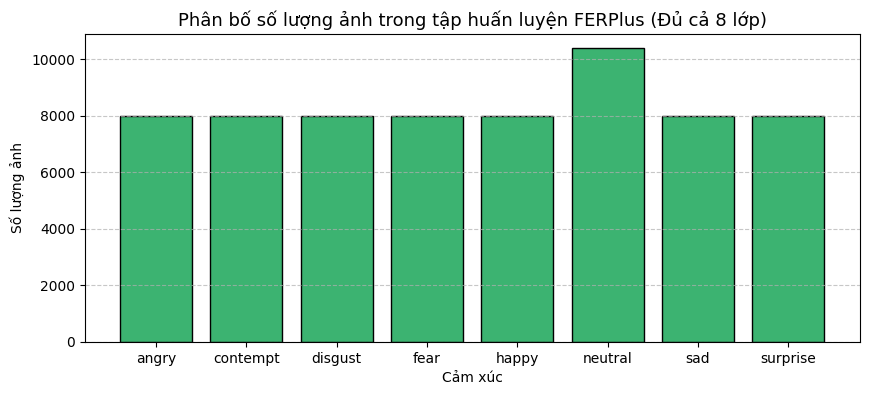

Class Weights cân bằng theo từng lớp:
{
  "angry": 1.0372,
  "contempt": 1.0372,
  "disgust": 1.0372,
  "fear": 1.0372,
  "happy": 1.0372,
  "neutral": 0.7994,
  "sad": 1.0372,
  "surprise": 1.0372
}


In [4]:
# 1. Nhận diện các thư mục thực tế có trong TRAIN_DIR
actual_folders = []
if TRAIN_DIR and os.path.exists(TRAIN_DIR):
    actual_folders = [f for f in os.listdir(TRAIN_DIR) if os.path.isdir(os.path.join(TRAIN_DIR, f))]

print("Các thư mục thực tế tìm thấy trong dataset:", actual_folders)

# Danh sách 8 lớp chuẩn
CLASS_NAMES = ['angry', 'contempt', 'disgust', 'fear', 'happy', 'neutral', 'sad', 'surprise']
NUM_CLASSES = 8

ALIAS_MAP_FIXED = {
    'anger': 'angry', 'angry': 'angry',
    'contempt': 'contempt', 'contemptuous': 'contempt',
    'disgust': 'disgust', 'disgusted': 'disgust',
    'fear': 'fear', 'fearful': 'fear',
    'happiness': 'happy', 'happy': 'happy',
    'neutral': 'neutral',
    'sadness': 'sad', 'sad': 'sad',
    'surprise': 'surprise', 'surprised': 'surprise',
    'suprise': 'surprise', 'suprised': 'surprise'   
}

# 2. Khớp thư mục
selected_dirs = []
folder_to_target_class = {}

for f in actual_folders:
    f_lower = f.lower().strip()
    target_cls = ALIAS_MAP_FIXED.get(f_lower, None)
    if not target_cls:
        if 'supr' in f_lower or 'surp' in f_lower:
            target_cls = 'surprise'
        else:
            for candidate in CLASS_NAMES:
                if candidate[:4] in f_lower:
                    target_cls = candidate
                    break
    if target_cls and target_cls in CLASS_NAMES:
        selected_dirs.append(f)
        folder_to_target_class[f] = target_cls

print(f"\nĐã khớp thành công {len(selected_dirs)} thư mục vào {NUM_CLASSES} cảm xúc:")
for f in selected_dirs:
    print(f" - Thư mục '{f}' -> Cảm xúc '{folder_to_target_class[f]}'")

# 3. Đếm số lượng ảnh từng lớp
class_counts = {cls: 0 for cls in CLASS_NAMES}
if TRAIN_DIR and os.path.exists(TRAIN_DIR):
    for f in selected_dirs:
        folder_path = os.path.join(TRAIN_DIR, f)
        count = len([x for x in os.listdir(folder_path) if x.lower().endswith(('.png', '.jpg', '.jpeg'))])
        target_cls = folder_to_target_class[f]
        class_counts[target_cls] += count

print("\nSố lượng ảnh mỗi lớp trong tập Train FERPlus:")
for k, v in class_counts.items():
    print(f" - {k:10s}: {v:,} ảnh")

# 4. Vẽ biểu đồ phân bố lớp
plt.figure(figsize=(10, 4))
plt.bar(class_counts.keys(), class_counts.values(), color='mediumseagreen', edgecolor='black')
plt.title(f"Phân bố số lượng ảnh trong tập huấn luyện FERPlus (Đủ cả {NUM_CLASSES} lớp)", fontsize=13)
plt.xlabel("Cảm xúc")
plt.ylabel("Số lượng ảnh")
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

# 5. Tính Class Weights cân bằng
y_train_mock = []
for idx, cls in enumerate(CLASS_NAMES):
    y_train_mock.extend([idx] * class_counts.get(cls, 0))

if len(y_train_mock) > 0:
    classes_unique = np.unique(y_train_mock)
    weights = compute_class_weight(class_weight='balanced', classes=classes_unique, y=y_train_mock)
    class_weight_dict = {int(i): float(w) for i, w in zip(classes_unique, weights)}
else:
    class_weight_dict = {int(i): 1.0 for i in range(NUM_CLASSES)}

weights_by_name = {CLASS_NAMES[k]: round(v, 4) for k, v in class_weight_dict.items()}
print("Class Weights cân bằng theo từng lớp:")
print(json.dumps(weights_by_name, indent=2))

### 4. Tiền Xử Lý Ảnh (CLAHE) & Khắc Phục Data Leakage
- Tách `TRAIN_DIR` thành **85% Train** và **15% Validation** bằng `validation_split=0.15`.
- Tập **TEST_DIR** giữ độc lập 100%, tuyệt đối không tham gia huấn luyện.
- Tiền xử lý bằng CLAHE (cân bằng sáng thích ứng) chuẩn hóa độ tương phản cục bộ khuôn mặt.

In [5]:
# Tiền xử lý CLAHE chuẩn hóa
clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))

def custom_clahe_preprocessing(img):
    img_uint8 = np.uint8(np.clip(img, 0, 255))
    if len(img_uint8.shape) == 3 and img_uint8.shape[-1] == 3:
        gray = cv2.cvtColor(img_uint8, cv2.COLOR_RGB2GRAY)
    else:
        gray = img_uint8.squeeze()
        
    clahe_img = clahe.apply(gray)
    clahe_img = clahe_img.astype('float32') / 255.0
    return np.expand_dims(clahe_img, axis=-1)

# Generator cho Train (có Augmentation hợp lý, không xoay lật quá mạnh)
train_datagen = ImageDataGenerator(
    preprocessing_function=custom_clahe_preprocessing,
    rotation_range=10,
    width_shift_range=0.1,
    height_shift_range=0.1,
    zoom_range=0.1,
    horizontal_flip=True,
    validation_split=0.15
)

# Generator cho Validation và Test (chỉ áp dụng CLAHE và chuẩn hóa)
val_test_datagen = ImageDataGenerator(
    preprocessing_function=custom_clahe_preprocessing,
    validation_split=0.15
)

In [6]:
# Khởi tạo data generators với danh sách các thư mục hợp lệ
load_classes = selected_dirs if len(selected_dirs) > 0 else CLASS_NAMES

if TRAIN_DIR and os.path.exists(TRAIN_DIR):
    train_generator = train_datagen.flow_from_directory(
        TRAIN_DIR,
        target_size=TARGET_SIZE,
        color_mode="grayscale",
        batch_size=BATCH_SIZE,
        class_mode="categorical",
        classes=load_classes,
        subset="training",
        shuffle=True,
        seed=SEED
    )

    validation_generator = val_test_datagen.flow_from_directory(
        TRAIN_DIR,
        target_size=TARGET_SIZE,
        color_mode="grayscale",
        batch_size=BATCH_SIZE,
        class_mode="categorical",
        classes=load_classes,
        subset="validation",
        shuffle=False,
        seed=SEED
    )
else:
    print("Vui lòng kiểm tra lại đường dẫn TRAIN_DIR!")
    train_generator, validation_generator = None, None

if TEST_DIR and os.path.exists(TEST_DIR):
    test_generator = val_test_datagen.flow_from_directory(
        TEST_DIR,
        target_size=TARGET_SIZE,
        color_mode="grayscale",
        batch_size=BATCH_SIZE,
        class_mode="categorical",
        classes=load_classes,
        shuffle=False
    )
else:
    print("Vui lòng kiểm tra lại đường dẫn TEST_DIR!")
    test_generator = None

Found 56423 images belonging to 8 classes.
Found 9956 images belonging to 8 classes.
Found 8341 images belonging to 8 classes.


### 5. Xây Dựng 3 Kiến Trúc Mô Hình Chuẩn Keras 3
1. **Model 1: Baseline Custom CNN** (Mô hình đối chứng ban đầu)
2. **Model 2: Improved CNN** (Thay `Flatten` bằng `GlobalAveragePooling2D`, bổ sung L2 Regularization)
3. **Model 3: MobileNetV3-Small** (Transfer Learning pretrained ImageNet với `Resizing(224, 224)`)

In [7]:
def build_baseline_cnn(input_shape=(48, 48, 1), num_classes=NUM_CLASSES):
    model = Sequential([
        Input(shape=input_shape),
        Conv2D(32, (3, 3), activation='relu', padding='same'),
        BatchNormalization(),
        MaxPooling2D((2, 2)),
        Dropout(0.25),

        Conv2D(64, (3, 3), activation='relu', padding='same'),
        BatchNormalization(),
        MaxPooling2D((2, 2)),
        Dropout(0.25),

        Conv2D(128, (3, 3), activation='relu', padding='same'),
        BatchNormalization(),
        MaxPooling2D((2, 2)),
        Dropout(0.25),

        Conv2D(256, (3, 3), activation='relu', padding='same'),
        BatchNormalization(),
        MaxPooling2D((2, 2)),
        Dropout(0.25),

        Flatten(),
        Dense(512, activation='relu'),
        BatchNormalization(),
        Dropout(0.5),

        Dense(256, activation='relu'),
        BatchNormalization(),
        Dropout(0.5),

        Dense(num_classes, activation='softmax')
    ], name="Baseline_CNN")
    return model

baseline_model = build_baseline_cnn()
baseline_model.summary()

I0000 00:00:1793546359.713484     436 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1793546359.715737     436 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


Model: "Baseline_CNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 48, 48, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 48, 48, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 24, 24, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 24, 24, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 24, 24, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 24, 24, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 12, 12, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 12, 12, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 12, 12, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 12, 12, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 6, 6, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 6, 6, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 6, 6, 256)      │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 6, 6, 256)      │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 3, 3, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 3, 3, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 2304)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │     1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 512)            │         2,048 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │             

 Total params: 1,706,376 (6.51 MB)

 Trainable params: 1,703,880 (6.50 MB)

 Non-trainable params: 2,496 (9.75 KB)

In [8]:
def build_improved_cnn(input_shape=(48, 48, 1), num_classes=NUM_CLASSES, l2_reg=1e-4):
    inputs = Input(shape=input_shape)
    
    # Block 1
    x = Conv2D(32, (3, 3), padding='same', activation='relu', kernel_regularizer=l2(l2_reg))(inputs)
    x = BatchNormalization()(x)
    x = Conv2D(32, (3, 3), padding='same', activation='relu', kernel_regularizer=l2(l2_reg))(x)
    x = BatchNormalization()(x)
    x = MaxPooling2D((2, 2))(x)
    x = Dropout(0.25)(x)

    # Block 2
    x = Conv2D(64, (3, 3), padding='same', activation='relu', kernel_regularizer=l2(l2_reg))(x)
    x = BatchNormalization()(x)
    x = Conv2D(64, (3, 3), padding='same', activation='relu', kernel_regularizer=l2(l2_reg))(x)
    x = BatchNormalization()(x)
    x = MaxPooling2D((2, 2))(x)
    x = Dropout(0.25)(x)

    # Block 3
    x = Conv2D(128, (3, 3), padding='same', activation='relu', kernel_regularizer=l2(l2_reg))(x)
    x = BatchNormalization()(x)
    x = Conv2D(128, (3, 3), padding='same', activation='relu', kernel_regularizer=l2(l2_reg))(x)
    x = BatchNormalization()(x)
    x = MaxPooling2D((2, 2))(x)
    x = Dropout(0.3)(x)

    # Block 4
    x = Conv2D(256, (3, 3), padding='same', activation='relu', kernel_regularizer=l2(l2_reg))(x)
    x = BatchNormalization()(x)
    x = MaxPooling2D((2, 2))(x)
    x = Dropout(0.35)(x)

    # GlobalAveragePooling2D thay cho Flatten: Giảm tham số thừa, triệt tiêu overfitting
    x = GlobalAveragePooling2D()(x)
    x = Dense(256, activation='relu', kernel_regularizer=l2(l2_reg))(x)
    x = BatchNormalization()(x)
    x = Dropout(0.5)(x)

    outputs = Dense(num_classes, activation='softmax')(x)
    model = Model(inputs=inputs, outputs=outputs, name="Improved_CNN_GAP")
    return model

improved_model = build_improved_cnn()
improved_model.summary()

Model: "Improved_CNN_GAP"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 48, 48, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 48, 48, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 48, 48, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 48, 48, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_7           │ (None, 48, 48, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 24, 24, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 24, 24, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 24, 24, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_8           │ (None, 24, 24, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 24, 24, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_9           │ (None, 24, 24, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 12, 12, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ (None, 12, 12, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 12, 12, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_10          │ (None, 12, 12, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)               │ (None, 12, 12, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_11          │ (None, 12, 12, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 6, 6, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_8 (Dropout)             │ (None, 6, 6, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_10 (Conv2D)              │ (None, 6, 6, 256)      │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_12          │ (None, 6, 6, 256)      │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼─────────────

 Total params: 653,288 (2.49 MB)

 Trainable params: 651,368 (2.48 MB)

 Non-trainable params: 1,920 (7.50 KB)

In [9]:
def build_mobilenetv3_model(input_shape=(48, 48, 1), num_classes=NUM_CLASSES):
    inputs = Input(shape=input_shape)
    # Lặp 1 channel grayscale thành 3 channels cho MobileNet
    x = Concatenate()([inputs, inputs, inputs])
    # Resize nội suy lên 224x224 để khớp chuẩn ImageNet của MobileNetV3 (khử cảnh báo và giữ receptive field chuẩn)
    x = Resizing(224, 224)(x)
    
    base_model = MobileNetV3Small(
        input_shape=(224, 224, 3),
        include_top=False,
        weights='imagenet'
    )
    base_model.trainable = False  # Đóng băng backbone
    
    x = base_model(x, training=False)
    x = GlobalAveragePooling2D()(x)
    x = BatchNormalization()(x)
    x = Dense(128, activation='relu')(x)
    x = Dropout(0.4)(x)
    outputs = Dense(num_classes, activation='softmax')(x)
    
    model = Model(inputs=inputs, outputs=outputs, name="MobileNetV3_Transfer")
    return model, base_model

mobilenet_model, mobilenet_base = build_mobilenetv3_model()
print("MobileNetV3-Small khởi tạo thành công.")

MobileNetV3-Small khởi tạo thành công.


### 6. Cấu Hình Callbacks & Huấn Luyện Mô Hình Được Chọn
- Vì FERPlus có nhãn sạch từ 10 chuyên gia, ta đặt `label_smoothing=0.02` (không cần làm mờ nhãn quá mức như FER-2013 cũ).
- Callbacks đồng bộ theo dõi `val_loss`.

In [10]:
# Thiết lập Callbacks đồng bộ
best_checkpoint_path = os.path.join(OUTPUT_MODEL_DIR, "emotion_model.keras")

callbacks = [
    EarlyStopping(
        monitor='val_loss',
        patience=10,
        restore_best_weights=True,
        verbose=1
    ),
    ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.5,
        patience=4,
        min_lr=1e-6,
        verbose=1
    ),
    ModelCheckpoint(
        filepath=best_checkpoint_path,
        monitor='val_loss',
        save_best_only=True,
        verbose=1
    )
]

optimizer = tf.keras.optimizers.Adam(learning_rate=1e-3)
# Với nhãn FERPlus sạch, label_smoothing nhỏ (0.02) giúp mô hình đạt độ chính xác tối đa
loss_fn = tf.keras.losses.CategoricalCrossentropy(label_smoothing=0.02)

improved_model.compile(
    optimizer=optimizer,
    loss=loss_fn,
    metrics=['accuracy']
)

print(f"Đã compile mô hình Improved CNN với loss_fn CategoricalCrossentropy (label_smoothing=0.02) và đồng bộ Callbacks theo val_loss.")

Đã compile mô hình Improved CNN với loss_fn CategoricalCrossentropy (label_smoothing=0.02) và đồng bộ Callbacks theo val_loss.


In [11]:
if train_generator and validation_generator:
    history = improved_model.fit(
        train_generator,
        epochs=EPOCHS,
        validation_data=validation_generator,
        class_weight=class_weight_dict,
        callbacks=callbacks
    )
else:
    print("Bỏ qua huấn luyện vì chưa nạp được dữ liệu.")
    history = None

Epoch 1/60
  1/441 ━━━━━━━━━━━━━━━━━━━━ 1:55:56 16s/step - accuracy: 0.0781 - loss: 3.7824

I0000 00:00:1793546378.049156     523 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


441/441 ━━━━━━━━━━━━━━━━━━━━ 0s 287ms/step - accuracy: 0.2015 - loss: 2.4838
Epoch 1: val_loss improved from None to 2.27611, saving model to models/emotion_model.keras

Epoch 1: finished saving model to models/emotion_model.keras
441/441 ━━━━━━━━━━━━━━━━━━━━ 283s 607ms/step - accuracy: 0.2669 - loss: 2.1558 - val_accuracy: 0.1783 - val_loss: 2.2761 - learning_rate: 0.0010
Epoch 2/60
441/441 ━━━━━━━━━━━━━━━━━━━━ 0s 265ms/step - accuracy: 0.4378 - loss: 1.6239
Epoch 2: val_loss improved from 2.27611 to 1.44535, saving model to models/emotion_model.keras

Epoch 2: finished saving model to models/emotion_model.keras
441/441 ━━━━━━━━━━━━━━━━━━━━ 132s 300ms/step - accuracy: 0.4673 - loss: 1.5511 - val_accuracy: 0.5262 - val_loss: 1.4453 - learning_rate: 0.0010
Epoch 3/60
441/441 ━━━━━━━━━━━━━━━━━━━━ 0s 265ms/step - accuracy: 0.5407 - loss: 1.3760
Epoch 3: val_loss improved from 1.44535 to 1.34690, saving model to models/emotion_model.keras

Epoch 3: finished saving model to models/emotion_m

### 7. Trực Quan Hóa Quá Trình Huấn Luyện (Loss & Accuracy Curves)

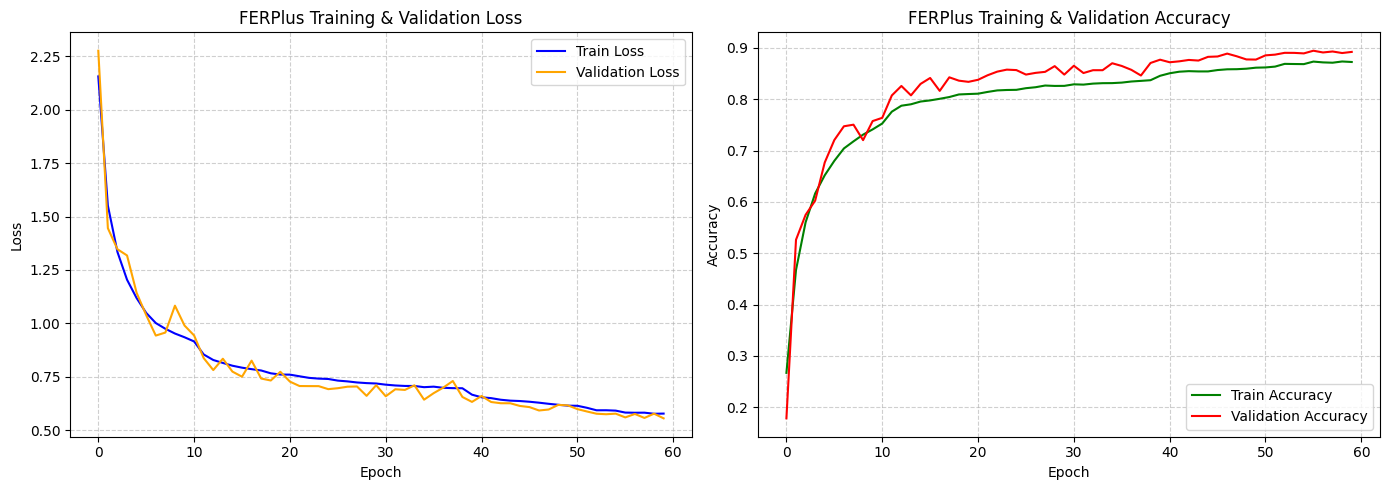

In [12]:
if history:
    plt.figure(figsize=(14, 5))

    # Loss Curve
    plt.subplot(1, 2, 1)
    plt.plot(history.history['loss'], label='Train Loss', color='blue')
    plt.plot(history.history['val_loss'], label='Validation Loss', color='orange')
    plt.title('FERPlus Training & Validation Loss', fontsize=12)
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.legend()
    plt.grid(True, linestyle='--', alpha=0.6)

    # Accuracy Curve
    plt.subplot(1, 2, 2)
    plt.plot(history.history['accuracy'], label='Train Accuracy', color='green')
    plt.plot(history.history['val_accuracy'], label='Validation Accuracy', color='red')
    plt.title('FERPlus Training & Validation Accuracy', fontsize=12)
    plt.xlabel('Epoch')
    plt.ylabel('Accuracy')
    plt.legend()
    plt.grid(True, linestyle='--', alpha=0.6)

    plt.tight_layout()
    plt.show()

### 8. Đánh Giá Khách Quan Trên Tập Test Độc Lập FERPlus
Đo đạc trên tập Test hoàn toàn độc lập với các metric chuẩn mực:
- Balanced Accuracy, Macro-F1, Weighted-F1
- Normalized Confusion Matrix (Heatmap chuẩn hóa)
- Classification Report chi tiết từng cảm xúc

In [18]:
if test_generator:
    test_generator.reset()
    y_true = test_generator.classes
    y_pred_probs = improved_model.predict(test_generator, verbose=1)
    y_pred = np.argmax(y_pred_probs, axis=1)

    macro_f1 = f1_score(y_true, y_pred, average='macro')
    weighted_f1 = f1_score(y_true, y_pred, average='weighted')
    balanced_acc = balanced_accuracy_score(y_true, y_pred)

    print("================ KẾT QUẢ ĐÁNH GIÁ TRÊN TẬP TEST ================")
    print(f"Balanced Accuracy : {balanced_acc * 100:.2f}%")
    print(f"Macro-F1 Score    : {macro_f1 * 100:.2f}%")
    print(f"Weighted-F1 Score : {weighted_f1 * 100:.2f}%")
    print("========================================================================")
    print("\nChi tiết Classification Report:")
    print(classification_report(y_true, y_pred, target_names=CLASS_NAMES, digits=4))

66/66 ━━━━━━━━━━━━━━━━━━━━ 13s 198ms/step
================ KẾT QUẢ ĐÁNH GIÁ TRÊN TẬP TEST ================
Balanced Accuracy : 70.14%
Macro-F1 Score    : 69.47%
Weighted-F1 Score : 69.84%

Chi tiết Classification Report:
              precision    recall  f1-score   support

       angry     0.5884    0.7790    0.6704      1000
    contempt     0.8538    0.3330    0.4791      1000
     disgust     0.7655    0.5550    0.6435      1000
        fear     0.8289    0.6780    0.7459      1000
       happy     0.8489    0.8650    0.8569      1000
     neutral     0.7268    0.8531    0.7849      1341
         sad     0.5629    0.6850    0.6180      1000
    surprise     0.6774    0.8630    0.7590      1000

    accuracy                         0.7076      8341
   macro avg     0.7316    0.7014    0.6947      8341
weighted avg     0.7314    0.7076    0.6984      8341



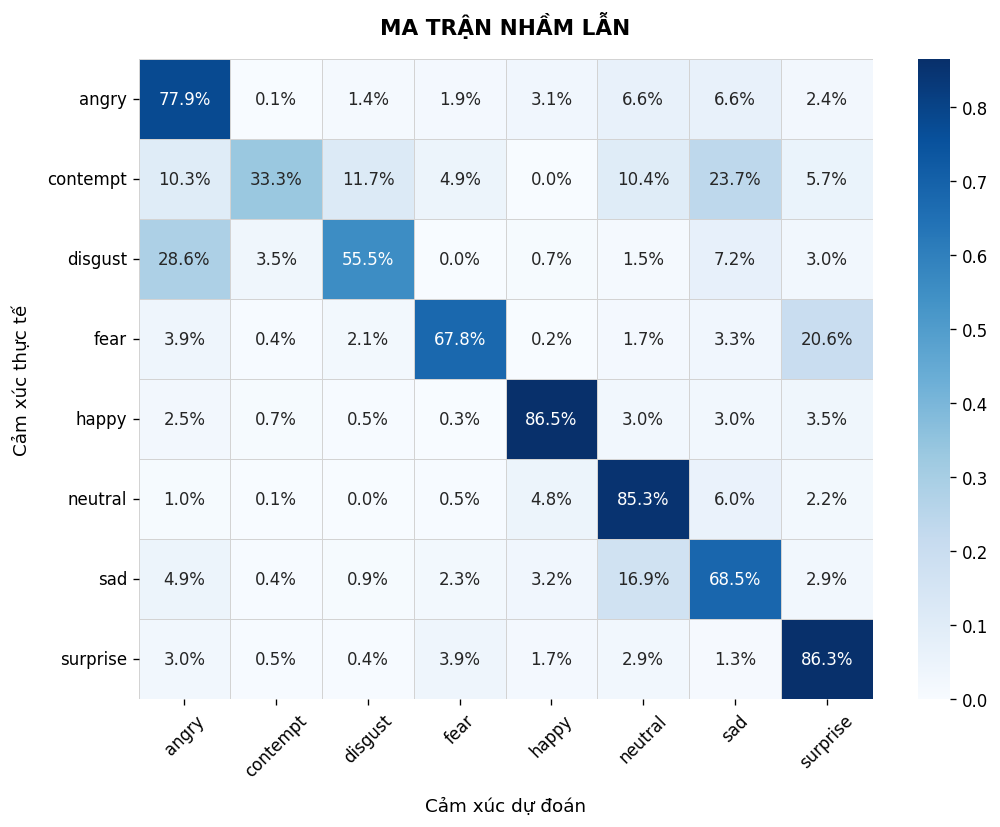


ĐỘ CHÍNH XÁC RIÊNG CỦA TỪNG CẢM XÚC:
 - Angry     :  77.90% (779/1000 ảnh)
 - Contempt  :  33.30% (333/1000 ảnh)
 - Disgust   :  55.50% (555/1000 ảnh)
 - Fear      :  67.80% (678/1000 ảnh)
 - Happy     :  86.50% (865/1000 ảnh)
 - Neutral   :  85.31% (1144/1341 ảnh)
 - Sad       :  68.50% (685/1000 ảnh)
 - Surprise  :  86.30% (863/1000 ảnh)


In [21]:
if test_generator:
    cm = confusion_matrix(y_true, y_pred)
    cm_sum = cm.sum(axis=1)[:, np.newaxis]
    cm_norm = np.divide(cm.astype('float'), cm_sum, out=np.zeros_like(cm, dtype=float), where=cm_sum != 0)

    plt.figure(figsize=(9, 7), dpi=120)
    sns.heatmap(cm_norm, annot=True, fmt='.1%', cmap='Blues',
                xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES,
                linewidths=0.5, linecolor='lightgray')
    plt.title("MA TRẬN NHẦM LẪN", fontsize=13, fontweight='bold', pad=15)
    plt.xlabel("Cảm xúc dự đoán", fontsize=11, labelpad=10)
    plt.ylabel("Cảm xúc thực tế", fontsize=11, labelpad=10)
    plt.xticks(rotation=45)
    plt.yticks(rotation=0)
    plt.tight_layout()
    plt.show()

    print("\n" + "="*55)
    print("ĐỘ CHÍNH XÁC RIÊNG CỦA TỪNG CẢM XÚC:")
    print("="*55)
    for idx, label_name in enumerate(CLASS_NAMES):
        acc = cm_norm[idx, idx] * 100
        total_samples = cm[idx].sum()
        correct_samples = cm[idx, idx]
        print(f" - {label_name.capitalize():10s}: {acc:6.2f}% ({correct_samples}/{total_samples} ảnh)")
    print("="*55)

### 9. Phân Tích Lỗi (Error Analysis)
Trực quan hóa các mẫu ảnh hiếm hoi bị mô hình phân loại sai trên tập Test FERPlus.

Tổng số mẫu đoán sai trên tập Test FERPlus: 2439 / 8341


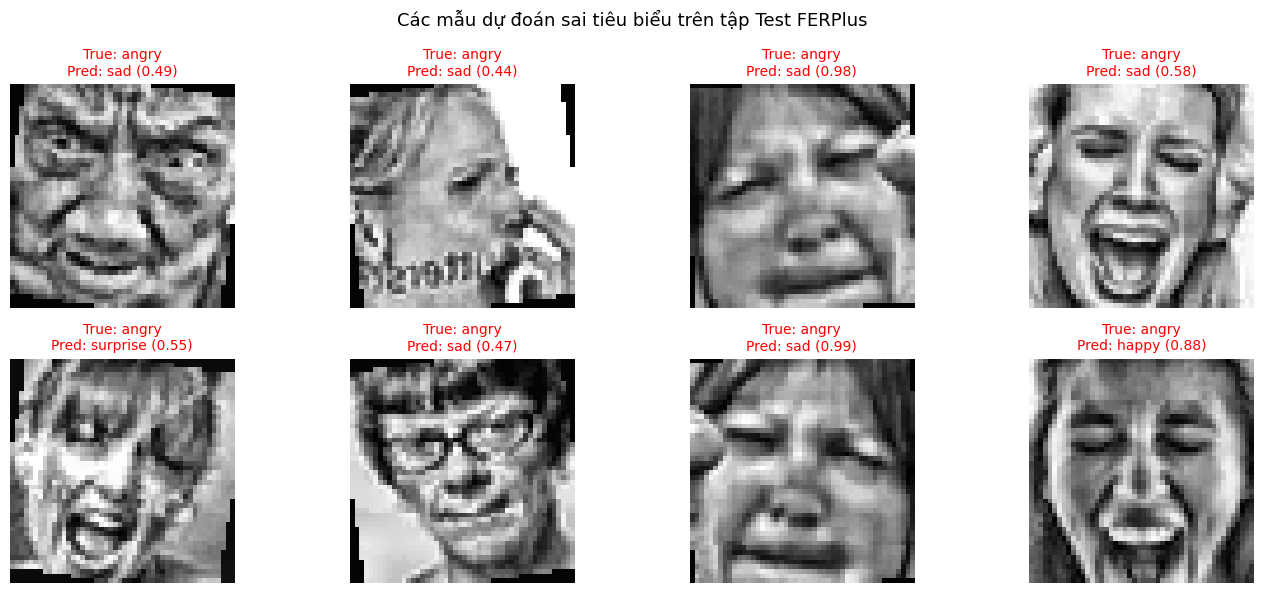

In [16]:
if test_generator:
    test_generator.reset()
    wrong_indices = np.where(y_pred != y_true)[0]
    print(f"Tổng số mẫu đoán sai trên tập Test FERPlus: {len(wrong_indices)} / {len(y_true)}")

    num_display = min(8, len(wrong_indices))
    if num_display > 0:
        plt.figure(figsize=(14, 6))
        for idx_i, err_idx in enumerate(wrong_indices[:num_display]):
            batch_idx = err_idx // BATCH_SIZE
            sample_in_batch = err_idx % BATCH_SIZE
            img_batch, _ = test_generator[batch_idx]
            sample_img = img_batch[sample_in_batch].squeeze()

            plt.subplot(2, 4, idx_i + 1)
            plt.imshow(sample_img, cmap='gray')
            plt.title(f"True: {CLASS_NAMES[y_true[err_idx]]}\nPred: {CLASS_NAMES[y_pred[err_idx]]} ({y_pred_probs[err_idx][y_pred[err_idx]]:.2f})", fontsize=10, color='red')
            plt.axis('off')
        plt.suptitle("Các mẫu dự đoán sai tiêu biểu trên tập Test FERPlus", fontsize=13)
        plt.tight_layout()
        plt.show()

### 10. Xuất Mô Hình & Metadata Phục Vụ Triển Khai Thực Tế

In [17]:
# 1. Lưu trọng số mô hình tốt nhất vào root và models/
improved_model.save("emotion_model.keras")
improved_model.save(os.path.join(OUTPUT_MODEL_DIR, "emotion_model.keras"))
print("Đã lưu mô hình: emotion_model.keras")

# 2. Xuất labels.json
labels_path = os.path.join(OUTPUT_MODEL_DIR, "labels.json")
with open(labels_path, "w", encoding="utf-8") as f:
    json.dump(CLASS_NAMES, f, ensure_ascii=False, indent=2)

with open("labels.json", "w", encoding="utf-8") as f:
    json.dump(CLASS_NAMES, f, ensure_ascii=False, indent=2)
print("Đã xuất nhãn:", CLASS_NAMES)

# 3. Xuất preprocessing_config.json
preprocessing_config = {
    "target_size": list(TARGET_SIZE),
    "color_mode": "grayscale",
    "use_clahe": True,
    "clahe_clip_limit": 2.0,
    "clahe_tile_grid_size": [8, 8],
    "normalize": True,
    "crop_padding": 0.15,
    "square_crop": True,
    "confidence_threshold": 0.35,
    "dataset": "FERPlus"
}

config_path = os.path.join(OUTPUT_MODEL_DIR, "preprocessing_config.json")
with open(config_path, "w", encoding="utf-8") as f:
    json.dump(preprocessing_config, f, ensure_ascii=False, indent=2)
print("Đã xuất cấu hình tiền xử lý:", config_path)

Đã lưu mô hình: emotion_model.keras
Đã xuất nhãn: ['angry', 'contempt', 'disgust', 'fear', 'happy', 'neutral', 'sad', 'surprise']
Đã xuất cấu hình tiền xử lý: models/preprocessing_config.json
